# MODULE 3: MACHINE LEARNING PRACTICALS AND MODEL IMPLEMENTATION
## Loan Default Prediction System

**Submitted by:** Advik Singh  
**Registration Number:** RA2411056030023  
**Branch/Section:** DS-A  
**Course:** Machine Learning / Data Science and Machine Learning Training

---

This notebook contains the complete implementation of all Module 3 practicals, covering:
1. Data Loading and Inspection
2. Exploratory Data Analysis (EDA)
3. Data Preprocessing and Train-Test Split
4. Logistic Regression
5. Decision Tree Classifier
6. Random Forest Classifier
7. Support Vector Machine (SVM)
8. K-Nearest Neighbours (KNN)
9. Gradient Boosting
10. AdaBoost
11. XGBoost (with detailed explanation)
12. CatBoost (supplementary comparison)
13. Model Comparison and Visualization
14. Feature Importance Analysis
15. Hyperparameter Tuning with GridSearchCV
16. Cross-Validation
17. Classification Reports and Final Evaluation


In [1]:
# ============================================================
# PRACTICAL 0 — Environment Setup & Imports
# ============================================================
import os
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, GridSearchCV, StratifiedKFold, cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)
from sklearn.utils.class_weight import compute_sample_weight

from xgboost import XGBClassifier
from catboost import CatBoostClassifier

warnings.filterwarnings("ignore")
sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 150

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Output directories
RESULTS_DIR = "results"
FIG_DIR = os.path.join(RESULTS_DIR, "figures")
os.makedirs(FIG_DIR, exist_ok=True)
print("Environment ready. Required libraries imported successfully.")


Environment ready. Required libraries imported successfully.


## Practical 1: Data Loading and Inspection

**Aim:** Load the loan default dataset and perform an initial inspection to understand its structure, data types, missing values, duplicates, and basic statistics.

**Theory:** Before building any machine learning model, we must understand the data. This step involves checking dimensions, column names, data types, summary statistics, missing values, and duplicate records.


In [2]:
# Load dataset
df = pd.read_csv("Module 3 Project Data.csv")
print(f"Raw dataset shape: {df.shape}")
print(f"Columns: {df.columns.tolist()}")

# Drop non-predictive Index and rename columns for easier handling
df = df.drop(columns=["Index"])
df = df.rename(columns={
    "Bank Balance": "Bank_Balance",
    "Annual Salary": "Annual_Salary",
    "Defaulted?": "Defaulted"
})

print(f"\nCleaned dataset shape: {df.shape}")
df.head()


Raw dataset shape: (10000, 5)
Columns: ['Index', 'Employed', 'Bank Balance', 'Annual Salary', 'Defaulted?']

Cleaned dataset shape: (10000, 4)


,Employed,Bank_Balance,Annual_Salary,Defaulted
0,1,8754.36,532339.56,0
1,0,9806.16,145273.56,0
2,1,12882.60,381205.68,0
3,1,6351.00,428453.88,0
4,1,9427.92,461562.00,0


In [3]:
# Data types and info
print("Data Types:")
print(df.dtypes)
print("\nMissing Values:")
print(df.isnull().sum())
print(f"\nDuplicate Rows: {df.duplicated().sum()}")
print("\nDescriptive Statistics:")
df.describe().round(2)


Data Types:
Employed           int64
Bank_Balance     float64
Annual_Salary    float64
Defaulted          int64
dtype: object

Missing Values:
Employed         0
Bank_Balance     0
Annual_Salary    0
Defaulted        0
dtype: int64

Duplicate Rows: 0

Descriptive Statistics:


,Employed,Bank_Balance,Annual_Salary,Defaulted
count,10000.00,10000.00,10000.00,10000.00
mean,0.71,10024.50,402203.78,0.03
std,0.46,5804.58,160039.67,0.18
min,0.00,0.00,9263.64,0.00
25%,0.00,5780.79,256085.52,0.00
50%,1.00,9883.62,414631.74,0.00
75%,1.00,13995.66,525692.76,0.00
max,1.00,31851.84,882650.76,1.00


In [4]:
# Identify column types
num_cols = ["Bank_Balance", "Annual_Salary"]
cat_cols = ["Employed"]
target_col = "Defaulted"

print(f"Numerical features: {num_cols}")
print(f"Categorical/binary features: {cat_cols}")
print(f"Target variable: {target_col}")
print(f"\nTarget distribution:\n{df['Defaulted'].value_counts()}")
print(f"\nTarget distribution (%):\n{df['Defaulted'].value_counts(normalize=True).round(4)*100}")


Numerical features: ['Bank_Balance', 'Annual_Salary']
Categorical/binary features: ['Employed']
Target variable: Defaulted

Target distribution:
Defaulted
0    9667
1     333
Name: count, dtype: int64

Target distribution (%):
Defaulted
0    96.67
1     3.33
Name: proportion, dtype: float64


## Practical 2: Exploratory Data Analysis (EDA)

**Aim:** Visualize and understand the distributions, relationships, and patterns in the data.

**Theory:** EDA helps identify patterns, outliers, class imbalance, feature correlations, and potential data quality issues before modeling.


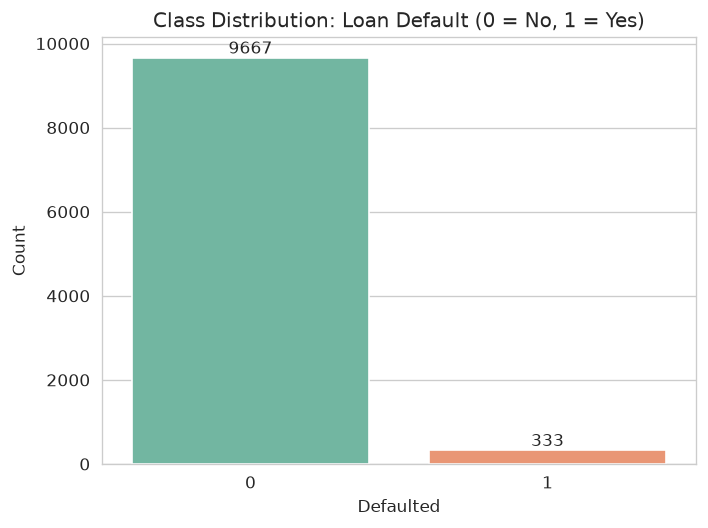

In [5]:
# Target variable distribution
fig, ax = plt.subplots(figsize=(6, 4.5))
sns.countplot(x="Defaulted", data=df, ax=ax, palette="Set2")
ax.set_title("Class Distribution: Loan Default (0 = No, 1 = Yes)")
ax.set_xlabel("Defaulted")
ax.set_ylabel("Count")
for p in ax.patches:
    ax.annotate(f"{int(p.get_height())}",
                (p.get_x() + p.get_width()/2., p.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig01_class_distribution.png"), bbox_inches="tight")
plt.show()


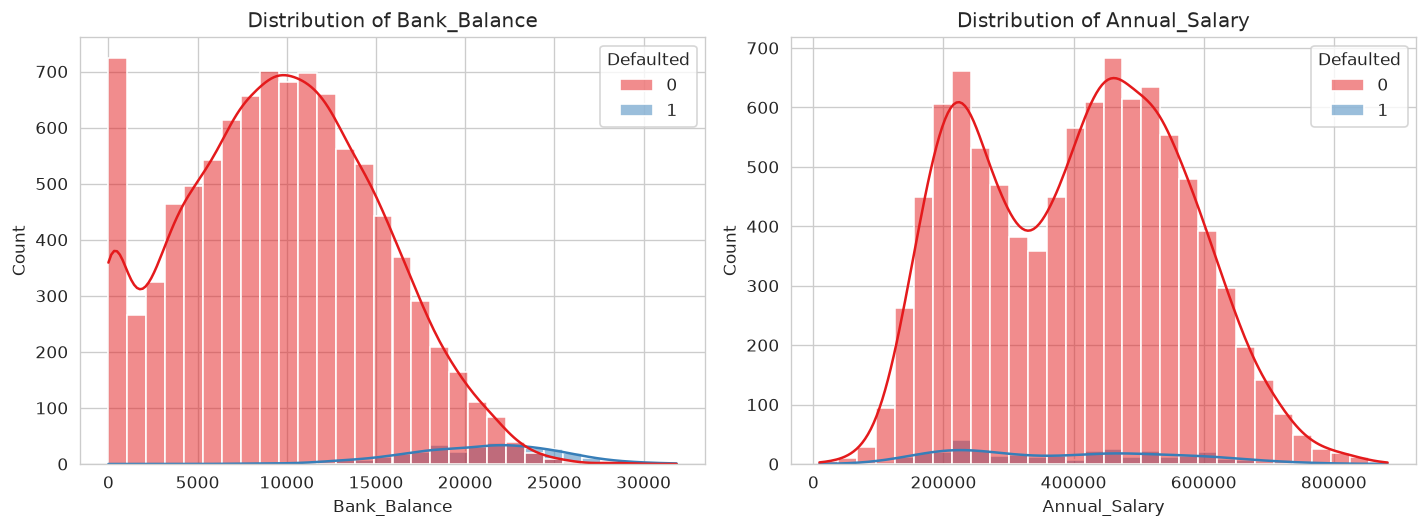

In [6]:
# Histograms of numerical features by target
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, num_cols):
    sns.histplot(data=df, x=col, hue="Defaulted", bins=30, kde=True, ax=ax,
                 palette="Set1", alpha=0.5)
    ax.set_title(f"Distribution of {col}")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig02_histograms.png"), bbox_inches="tight")
plt.show()


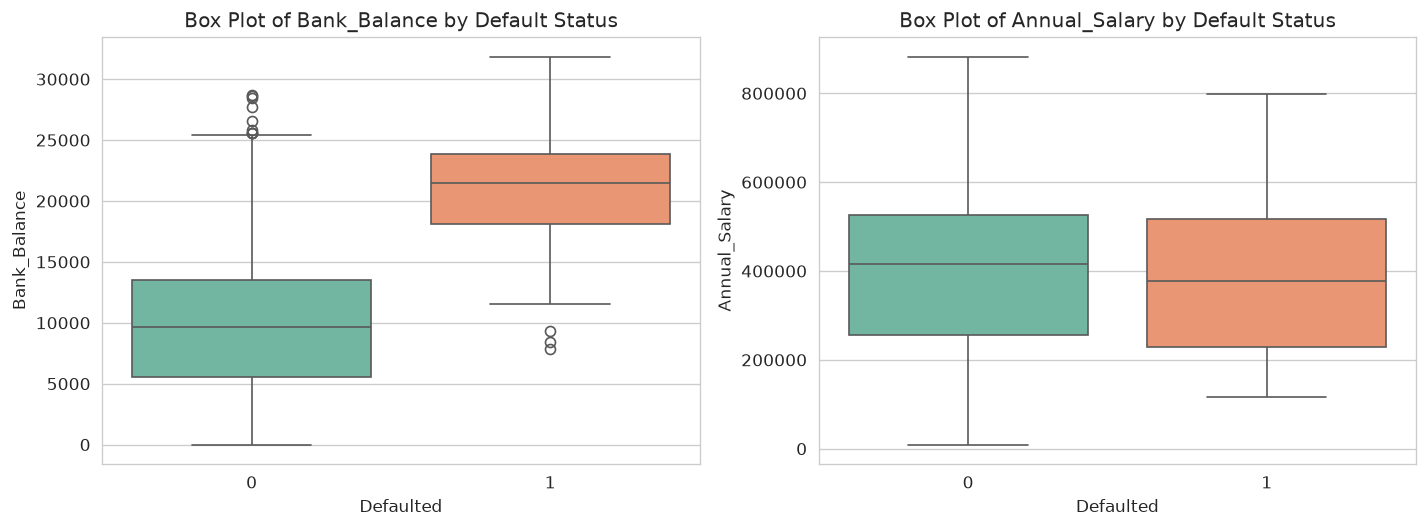

In [7]:
# Box plots for outlier detection
fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col in zip(axes, num_cols):
    sns.boxplot(x="Defaulted", y=col, data=df, ax=ax, palette="Set2")
    ax.set_title(f"Box Plot of {col} by Default Status")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig03_boxplots.png"), bbox_inches="tight")
plt.show()


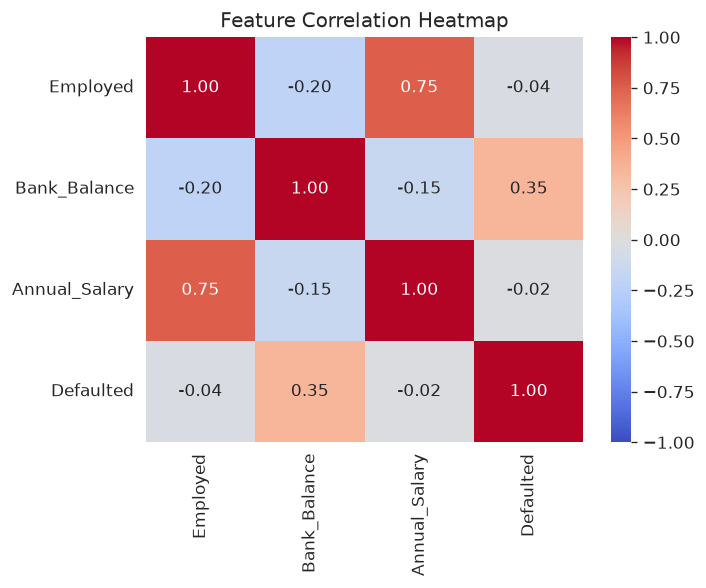

Correlation with target (Defaulted):


Defaulted        1.0000
Bank_Balance     0.3501
Annual_Salary   -0.0199
Employed        -0.0354
Name: Defaulted, dtype: float64

In [8]:
# Correlation heatmap
fig, ax = plt.subplots(figsize=(6, 5))
corr = df.corr()
sns.heatmap(corr, annot=True, cmap="coolwarm", fmt=".2f", ax=ax,
            vmin=-1, vmax=1, center=0)
ax.set_title("Feature Correlation Heatmap")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig04_correlation_heatmap.png"), bbox_inches="tight")
plt.show()
print("Correlation with target (Defaulted):")
corr["Defaulted"].sort_values(ascending=False).round(4)


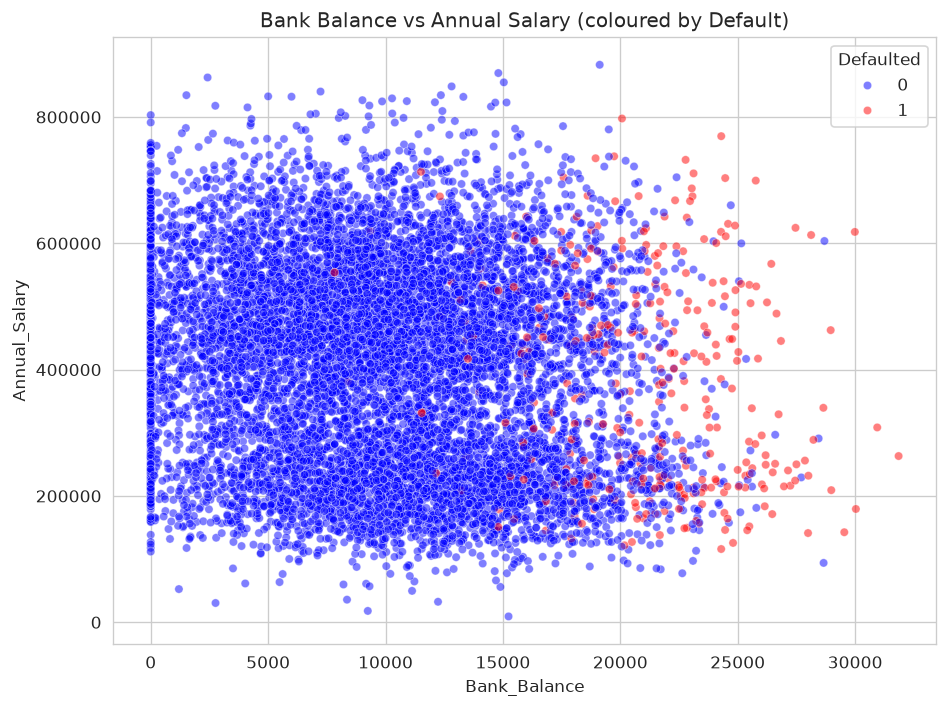

In [9]:
# Scatter plot: Bank Balance vs Annual Salary
fig, ax = plt.subplots(figsize=(8, 6))
sns.scatterplot(data=df, x="Bank_Balance", y="Annual_Salary",
                hue="Defaulted", palette={0: "blue", 1: "red"},
                alpha=0.5, s=25, ax=ax)
ax.set_title("Bank Balance vs Annual Salary (coloured by Default)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig05_scatter_balance_salary.png"), bbox_inches="tight")
plt.show()


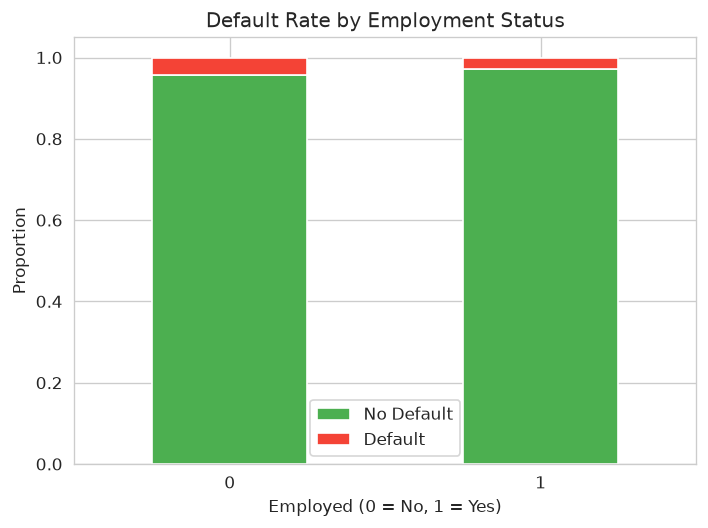

In [10]:
# Default rate by employment status
fig, ax = plt.subplots(figsize=(6, 4.5))
ct = pd.crosstab(df["Employed"], df["Defaulted"], normalize="index")
ct.plot(kind="bar", stacked=True, ax=ax, color=["#4CAF50", "#F44336"])
ax.set_title("Default Rate by Employment Status")
ax.set_xlabel("Employed (0 = No, 1 = Yes)")
ax.set_ylabel("Proportion")
ax.legend(["No Default", "Default"])
plt.xticks(rotation=0)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig06_employment_default.png"), bbox_inches="tight")
plt.show()


## Practical 3: Data Preprocessing and Train-Test Split

**Aim:** Prepare the data for modeling by separating features and target, splitting into train/test sets, and applying feature scaling where needed.

**Theory:** 
- **Train-test split** reserves a portion of data for unbiased model evaluation. We use **stratified splitting** to preserve class balance in both sets.
- **Feature scaling** (StandardScaler: zero mean, unit variance) is required for distance/gradient-based algorithms (Logistic Regression, SVM, KNN), while tree-based models are scale-invariant.
- **No missing values or duplicates** exist in this dataset so no imputation is needed.
- **Data leakage prevention:** The scaler is fit only on training data; the test set is transformed using training-set statistics.


In [11]:
X = df.drop(columns=["Defaulted"])
y = df["Defaulted"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
spw = neg_count / pos_count  # scale_pos_weight for XGBoost

print(f"Train set: {X_train.shape[0]} samples, positive rate = {y_train.mean():.4f}")
print(f"Test set:  {X_test.shape[0]} samples, positive rate = {y_test.mean():.4f}")
print(f"scale_pos_weight for XGBoost: {spw:.2f}")


Train set: 8000 samples, positive rate = 0.0333
Test set:  2000 samples, positive rate = 0.0335
scale_pos_weight for XGBoost: 29.08


In [12]:
# Helper function to train and evaluate any model
def evaluate_model(name, model, X_tr, y_tr, X_te, y_te):
    model.fit(X_tr, y_tr)
    y_pred = model.predict(X_te)
    if hasattr(model, "predict_proba"):
        y_prob = model.predict_proba(X_te)[:, 1]
    else:
        y_prob = model.decision_function(X_te)
        y_prob = 1 / (1 + np.exp(-y_prob))
    return {
        "accuracy":  accuracy_score(y_te, y_pred),
        "precision": precision_score(y_te, y_pred, zero_division=0),
        "recall":    recall_score(y_te, y_pred, zero_division=0),
        "f1":        f1_score(y_te, y_pred, zero_division=0),
        "roc_auc":   roc_auc_score(y_te, y_prob),
        "cm":        confusion_matrix(y_te, y_pred),
        "y_pred":    y_pred,
        "y_prob":    y_prob,
        "model":     model,
    }

all_models = {}
model_objs = {}


## Practical 4: Logistic Regression

**Aim:** Implement Logistic Regression for binary classification of loan defaults.

**Theory:**  
Logistic Regression models the probability of a binary outcome using the sigmoid function:  
**p = 1 / (1 + e^(-z))** where **z = β₀ + β₁x₁ + ... + βₙxₙ**.

**Advantages:** Fast, interpretable (coefficients show direction/magnitude of feature effects), outputs well-calibrated probabilities.  
**Limitations:** Assumes linearity in the log-odds, sensitive to feature scale and outliers.

We use `class_weight="balanced"` to counter class imbalance.


In [13]:
logreg = LogisticRegression(max_iter=2000, class_weight="balanced", random_state=RANDOM_STATE)
logreg_metrics = evaluate_model("Logistic Regression", logreg,
                                X_train_scaled, y_train, X_test_scaled, y_test)
all_models["Logistic Regression"] = logreg_metrics
model_objs["Logistic Regression"] = logreg

print(f"Accuracy:  {logreg_metrics['accuracy']:.4f}")
print(f"Precision: {logreg_metrics['precision']:.4f}")
print(f"Recall:    {logreg_metrics['recall']:.4f}")
print(f"F1:        {logreg_metrics['f1']:.4f}")
print(f"ROC-AUC:   {logreg_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", logreg_metrics["cm"])


Accuracy:  0.8550
Precision: 0.1730
Recall:    0.8806
F1:        0.2892
ROC-AUC:   0.9487
Confusion Matrix:
 [[1651  282]
 [   8   59]]


## Practical 5: Decision Tree Classifier

**Aim:** Build a Decision Tree classifier and visualize its structure.

**Theory:** A Decision Tree splits data at each node based on a feature threshold, creating a tree of decisions leading to leaf-node predictions.

**Key parameters:** `max_depth` (limits tree depth to prevent overfitting), `min_samples_split`, `min_samples_leaf`, `criterion` (gini/entropy).  
**Advantages:** Interpretable, handles non-linear relationships, no scaling needed.  
**Limitations:** Prone to overfitting, unstable to small data changes.


Accuracy:  0.8625
Precision: 0.1750
Recall:    0.8358
F1:        0.2894
ROC-AUC:   0.9230
Confusion Matrix:
 [[1669  264]
 [  11   56]]


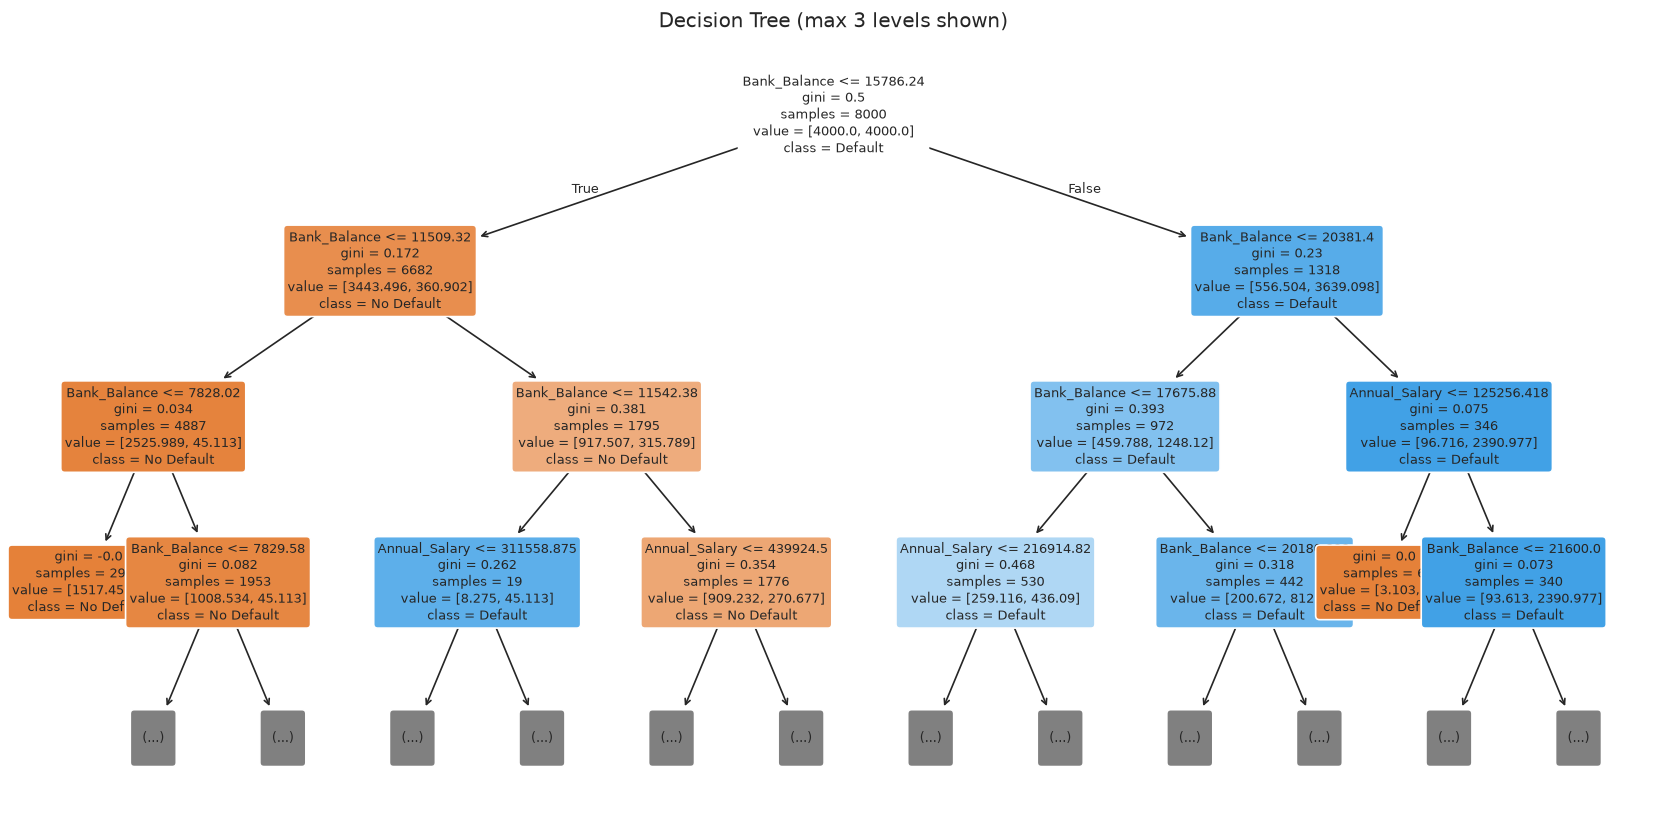

In [14]:
dt = DecisionTreeClassifier(random_state=RANDOM_STATE, class_weight="balanced", max_depth=5)
dt_metrics = evaluate_model("Decision Tree", dt, X_train, y_train, X_test, y_test)
all_models["Decision Tree"] = dt_metrics
model_objs["Decision Tree"] = dt

print(f"Accuracy:  {dt_metrics['accuracy']:.4f}")
print(f"Precision: {dt_metrics['precision']:.4f}")
print(f"Recall:    {dt_metrics['recall']:.4f}")
print(f"F1:        {dt_metrics['f1']:.4f}")
print(f"ROC-AUC:   {dt_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", dt_metrics["cm"])

# Visualize the tree
fig, ax = plt.subplots(figsize=(14, 7))
plot_tree(dt, feature_names=X.columns, class_names=["No Default", "Default"],
          filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title("Decision Tree (max 3 levels shown)")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig08_decision_tree.png"), bbox_inches="tight")
plt.show()


## Practical 6: Random Forest Classifier

**Aim:** Implement Random Forest, an ensemble of decision trees using bagging.

**Theory:** Random Forest trains many decision trees on bootstrap samples of the data, and at each split considers only a random subset of features. Final predictions are made by majority vote. This reduces variance compared to a single tree.

**Bagging (Bootstrap Aggregating):** Samples drawn with replacement; trees are independent.  
**Key parameters:** `n_estimators`, `max_depth`, `max_features`.


In [15]:
rf = RandomForestClassifier(n_estimators=300, class_weight="balanced",
                            random_state=RANDOM_STATE, n_jobs=-1)
rf_metrics = evaluate_model("Random Forest", rf, X_train, y_train, X_test, y_test)
all_models["Random Forest"] = rf_metrics
model_objs["Random Forest"] = rf

print(f"Accuracy:  {rf_metrics['accuracy']:.4f}")
print(f"Precision: {rf_metrics['precision']:.4f}")
print(f"Recall:    {rf_metrics['recall']:.4f}")
print(f"F1:        {rf_metrics['f1']:.4f}")
print(f"ROC-AUC:   {rf_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", rf_metrics["cm"])


Accuracy:  0.9615
Precision: 0.4405
Recall:    0.5522
F1:        0.4901
ROC-AUC:   0.9053
Confusion Matrix:
 [[1886   47]
 [  30   37]]


## Practical 7: Support Vector Machine (SVM)

**Aim:** Train an SVM with RBF kernel for default prediction.

**Theory:** SVM finds a hyperplane that maximises the margin between classes. The **kernel trick** (RBF kernel) maps data to higher dimensions where a linear separator exists.

**Key parameters:** `C` (regularization/margin trade-off), `gamma` (RBF width), `kernel`.  
SVMs require feature scaling and are sensitive to class imbalance (addressed via `class_weight="balanced"`).


In [16]:
svm = SVC(kernel="rbf", probability=True, class_weight="balanced", random_state=RANDOM_STATE)
svm_metrics = evaluate_model("SVM (RBF)", svm, X_train_scaled, y_train, X_test_scaled, y_test)
all_models["SVM (RBF)"] = svm_metrics
model_objs["SVM (RBF)"] = svm

print(f"Accuracy:  {svm_metrics['accuracy']:.4f}")
print(f"Precision: {svm_metrics['precision']:.4f}")
print(f"Recall:    {svm_metrics['recall']:.4f}")
print(f"F1:        {svm_metrics['f1']:.4f}")
print(f"ROC-AUC:   {svm_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", svm_metrics["cm"])


Accuracy:  0.8410
Precision: 0.1617
Recall:    0.8955
F1:        0.2740
ROC-AUC:   0.9152
Confusion Matrix:
 [[1622  311]
 [   7   60]]


## Practical 8: K-Nearest Neighbours (KNN)

**Aim:** Classify customers using the KNN algorithm.

**Theory:** KNN is a lazy, instance-based algorithm that classifies a new point by majority vote of its **k** nearest training neighbours. Distance metric (e.g. Euclidean) drives the predictions.

**Key parameter:** `n_neighbors` (k). Small k → sensitive to noise; large k → smoother boundaries. KNN requires feature scaling because distance metrics are scale-sensitive.


In [17]:
knn = KNeighborsClassifier(n_neighbors=11, weights="distance")
knn_metrics = evaluate_model("KNN", knn, X_train_scaled, y_train, X_test_scaled, y_test)
all_models["KNN"] = knn_metrics
model_objs["KNN"] = knn

print(f"Accuracy:  {knn_metrics['accuracy']:.4f}")
print(f"Precision: {knn_metrics['precision']:.4f}")
print(f"Recall:    {knn_metrics['recall']:.4f}")
print(f"F1:        {knn_metrics['f1']:.4f}")
print(f"ROC-AUC:   {knn_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", knn_metrics["cm"])


Accuracy:  0.9680
Precision: 0.5385
Recall:    0.3134
F1:        0.3962
ROC-AUC:   0.8395
Confusion Matrix:
 [[1915   18]
 [  46   21]]


## Practical 9: Gradient Boosting Classifier

**Aim:** Apply Gradient Boosting, a sequential ensemble method.

**Theory:** Unlike Random Forest (parallel bagging), Gradient Boosting builds trees sequentially. Each new tree is fit to the **residual errors** (negative gradient) of the previous ensemble, gradually reducing the loss function.

**Boosting vs Bagging:**  
- **Bagging (RF):** Independent trees on bootstrap samples; reduces variance.  
- **Boosting (GB):** Sequential trees correcting previous errors; reduces bias.  

**Key parameters:** `n_estimators`, `learning_rate` (shrinkage), `max_depth`.


In [18]:
gb = GradientBoostingClassifier(n_estimators=300, max_depth=3,
                                learning_rate=0.05, random_state=RANDOM_STATE)
gb_metrics = evaluate_model("Gradient Boosting", gb, X_train, y_train, X_test, y_test)
all_models["Gradient Boosting"] = gb_metrics
model_objs["Gradient Boosting"] = gb

print(f"Accuracy:  {gb_metrics['accuracy']:.4f}")
print(f"Precision: {gb_metrics['precision']:.4f}")
print(f"Recall:    {gb_metrics['recall']:.4f}")
print(f"F1:        {gb_metrics['f1']:.4f}")
print(f"ROC-AUC:   {gb_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", gb_metrics["cm"])


Accuracy:  0.9685
Precision: 0.5714
Recall:    0.2388
F1:        0.3368
ROC-AUC:   0.9454
Confusion Matrix:
 [[1921   12]
 [  51   16]]


## Practical 10: AdaBoost Classifier

**Aim:** Implement AdaBoost, an adaptive boosting algorithm.

**Theory:** AdaBoost (Adaptive Boosting) fits sequential weak learners (typically shallow decision stumps) while adjusting sample weights: misclassified instances receive higher weights so subsequent learners focus on them. Final prediction is a weighted vote.

We use `compute_sample_weight(class_weight="balanced")` to handle class imbalance since AdaBoost does not have a built-in `class_weight` parameter.


In [19]:
ada = AdaBoostClassifier(n_estimators=300, learning_rate=0.1, random_state=RANDOM_STATE)
sample_weights = compute_sample_weight(class_weight="balanced", y=y_train)
ada.fit(X_train, y_train, sample_weight=sample_weights)
y_pred_ada = ada.predict(X_test)
y_prob_ada = ada.predict_proba(X_test)[:, 1]
ada_metrics = {
    "accuracy":  accuracy_score(y_test, y_pred_ada),
    "precision": precision_score(y_test, y_pred_ada, zero_division=0),
    "recall":    recall_score(y_test, y_pred_ada, zero_division=0),
    "f1":        f1_score(y_test, y_pred_ada, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, y_prob_ada),
    "cm":        confusion_matrix(y_test, y_pred_ada),
    "y_pred":    y_pred_ada,
    "y_prob":    y_prob_ada,
    "model":     ada,
}
all_models["AdaBoost"] = ada_metrics
model_objs["AdaBoost"] = ada

print(f"Accuracy:  {ada_metrics['accuracy']:.4f}")
print(f"Precision: {ada_metrics['precision']:.4f}")
print(f"Recall:    {ada_metrics['recall']:.4f}")
print(f"F1:        {ada_metrics['f1']:.4f}")
print(f"ROC-AUC:   {ada_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", ada_metrics["cm"])


Accuracy:  0.8550
Precision: 0.1711
Recall:    0.8657
F1:        0.2857
ROC-AUC:   0.9464
Confusion Matrix:
 [[1652  281]
 [   9   58]]


## Practical 11: XGBoost — Detailed Implementation

**Aim:** Train and configure an XGBoost classifier, explaining its key hyperparameters.

### XGBoost Theory (Extreme Gradient Boosting)

XGBoost is an optimized, scalable implementation of gradient boosted trees. Key characteristics:

1. **Sequential tree building:** Trees are added one at a time; each new tree corrects the errors of the existing ensemble.
2. **Objective function:** Combines a loss function (e.g. log-loss for classification) with regularization:
   **Obj = Σ L(yᵢ, ŷᵢ) + Σ Ω(fₖ)**  
   where Ω(f) = γT + ½λ||w||² penalizes tree complexity (T = number of leaves, w = leaf weights).
3. **Key hyperparameters:**
   - `n_estimators`: Number of boosting rounds.
   - `learning_rate` (η): Shrinks each tree's contribution; smaller values require more trees but yield better generalization.
   - `max_depth`: Maximum depth of individual trees (controls overfitting).
   - `subsample`: Fraction of samples used per tree (stochastic gradient boosting).
   - `colsample_bytree`: Fraction of features sampled per split.
   - `reg_alpha` (α, L1) and `reg_lambda` (λ, L2): Regularization terms on leaf weights.
   - `scale_pos_weight`: Controls balance of positive and negative weights; useful for imbalanced classes.
   - `eval_metric`: Evaluation metric (e.g. `logloss`, `auc`).
4. **Built-in regularization:** L1/L2 penalties, shrinkage, column/row subsampling all help prevent overfitting.
5. **Feature importance:** XGBoost reports gain, weight, and cover based importance measures.


In [20]:
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    reg_alpha=0.1,
    reg_lambda=1.0,
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    verbosity=0,
)
xgb_metrics = evaluate_model("XGBoost", xgb, X_train, y_train, X_test, y_test)
all_models["XGBoost"] = xgb_metrics
model_objs["XGBoost"] = xgb

print(f"Accuracy:  {xgb_metrics['accuracy']:.4f}")
print(f"Precision: {xgb_metrics['precision']:.4f}")
print(f"Recall:    {xgb_metrics['recall']:.4f}")
print(f"F1:        {xgb_metrics['f1']:.4f}")
print(f"ROC-AUC:   {xgb_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", xgb_metrics["cm"])


Accuracy:  0.8845
Precision: 0.1917
Recall:    0.7612
F1:        0.3063
ROC-AUC:   0.9356
Confusion Matrix:
 [[1718  215]
 [  16   51]]


## Practical 12: CatBoost Classifier (Supplementary Comparison)

**Aim:** Train a CatBoost model as a supplementary comparison.

**CatBoost** ("Categorical Boosting") is a gradient boosting library that natively handles categorical features without manual one-hot encoding through ordered boosting and target encoding statistics. It reduces overfitting via ordered boosting and provides strong out-of-the-box performance.

**Key features:** Automatic handling of categorical variables, built-in class balancing (`auto_class_weights="Balanced"`), minimal preprocessing needed.


In [21]:
cat = CatBoostClassifier(
    iterations=300,
    depth=4,
    learning_rate=0.05,
    auto_class_weights="Balanced",
    verbose=0,
    random_state=RANDOM_STATE,
)
cat_metrics = evaluate_model("CatBoost", cat, X_train, y_train, X_test, y_test)
all_models["CatBoost"] = cat_metrics
model_objs["CatBoost"] = cat

print(f"Accuracy:  {cat_metrics['accuracy']:.4f}")
print(f"Precision: {cat_metrics['precision']:.4f}")
print(f"Recall:    {cat_metrics['recall']:.4f}")
print(f"F1:        {cat_metrics['f1']:.4f}")
print(f"ROC-AUC:   {cat_metrics['roc_auc']:.4f}")
print("Confusion Matrix:\n", cat_metrics["cm"])


Accuracy:  0.8755
Precision: 0.1926
Recall:    0.8507
F1:        0.3140
ROC-AUC:   0.9371
Confusion Matrix:
 [[1694  239]
 [  10   57]]


## Practical 13: Model Comparison and Visualization

**Aim:** Consolidate all model results, rank them, and produce comparative visualizations.

**Evaluation Metrics for Imbalanced Classification:**
- **Accuracy:** Overall correctness (misleading for imbalanced data).
- **Precision:** TP / (TP + FP) — how many predicted positives are actual positives.
- **Recall (Sensitivity):** TP / (TP + FN) — how many actual positives are caught.
- **F1-score:** Harmonic mean of precision and recall.
- **ROC-AUC:** Area under the ROC curve — measures ability to distinguish classes across thresholds.


In [22]:
results_df = pd.DataFrame({
    name: {k: v for k, v in m.items() if k not in ("cm", "y_pred", "y_prob", "model")}
    for name, m in all_models.items()
}).T
results_df = results_df.sort_values("roc_auc", ascending=False).round(4)
results_df.to_csv(os.path.join(RESULTS_DIR, "model_comparison.csv"))
results_df


,accuracy,precision,recall,f1,roc_auc
Logistic Regression,0.8550,0.1730,0.8806,0.2892,0.9487
AdaBoost,0.8550,0.1711,0.8657,0.2857,0.9464
Gradient Boosting,0.9685,0.5714,0.2388,0.3368,0.9454
CatBoost,0.8755,0.1926,0.8507,0.3140,0.9371
XGBoost,0.8845,0.1917,0.7612,0.3063,0.9356
Decision Tree,0.8625,0.1750,0.8358,0.2894,0.9230
SVM (RBF),0.8410,0.1617,0.8955,0.2740,0.9152
Random Forest,0.9615,0.4405,0.5522,0.4901,0.9053
KNN,0.9680,0.5385,0.3134,0.3962,0.8395


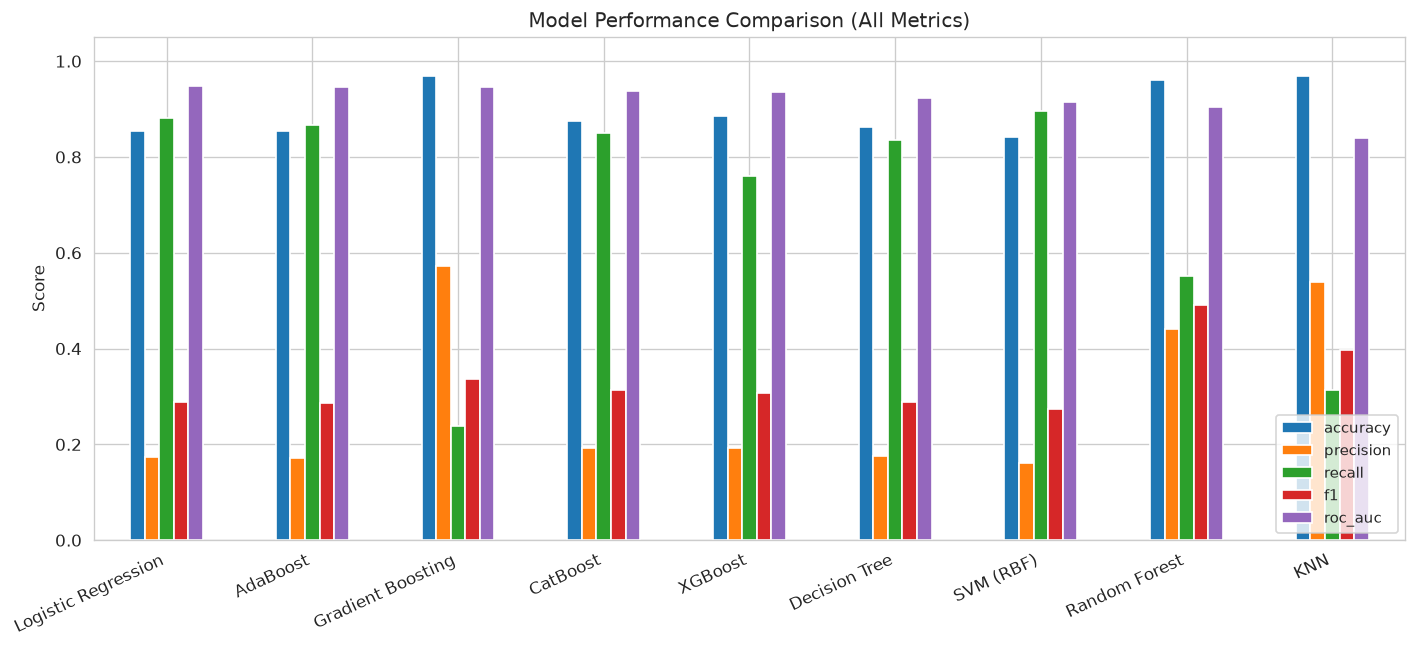

In [23]:
# Bar chart comparison
fig, ax = plt.subplots(figsize=(12, 5.5))
metrics_to_plot = ["accuracy", "precision", "recall", "f1", "roc_auc"]
results_df[metrics_to_plot].plot(kind="bar", ax=ax)
ax.set_title("Model Performance Comparison (All Metrics)")
ax.set_ylabel("Score")
ax.set_ylim(0, 1.05)
ax.set_xticklabels(results_df.index, rotation=25, ha="right")
ax.legend(loc="lower right", fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig09_model_comparison_bar.png"), bbox_inches="tight")
plt.show()


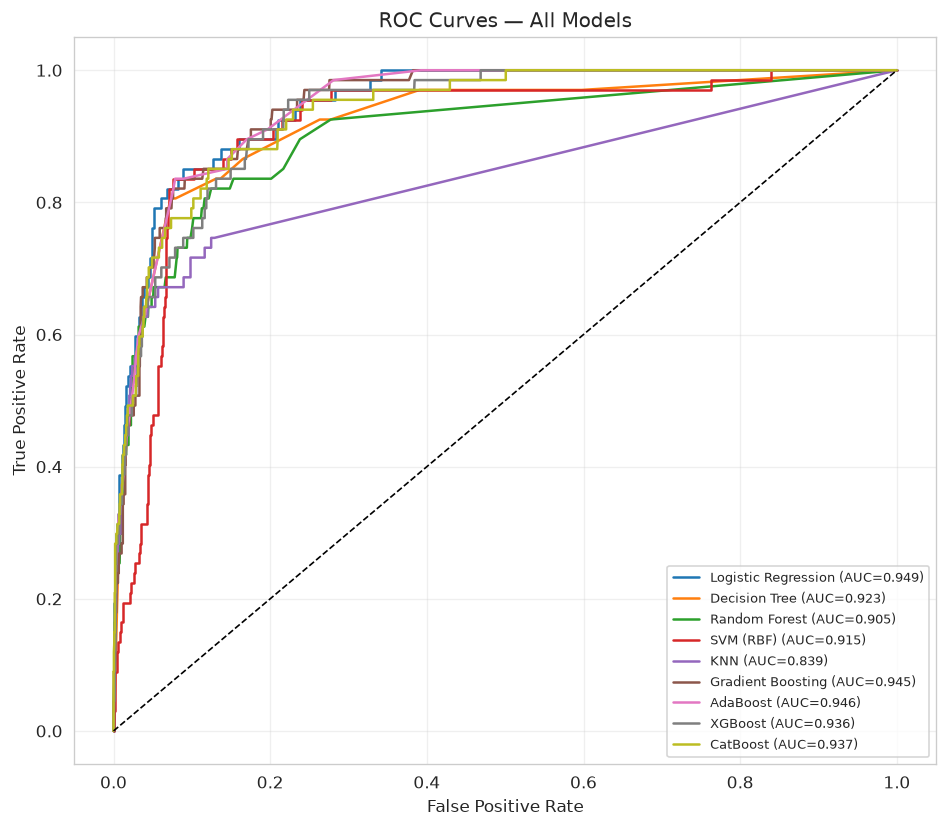

In [24]:
# ROC curves
fig, ax = plt.subplots(figsize=(8, 7))
for name, m in all_models.items():
    fpr, tpr, _ = roc_curve(y_test, m["y_prob"])
    ax.plot(fpr, tpr, label=f"{name} (AUC={m['roc_auc']:.3f})", linewidth=1.5)
ax.plot([0, 1], [0, 1], "k--", linewidth=1)
ax.set_xlabel("False Positive Rate")
ax.set_ylabel("True Positive Rate")
ax.set_title("ROC Curves — All Models")
ax.legend(loc="lower right", fontsize=8)
ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig10_roc_curves.png"), bbox_inches="tight")
plt.show()


Best model (by ROC-AUC): Logistic Regression


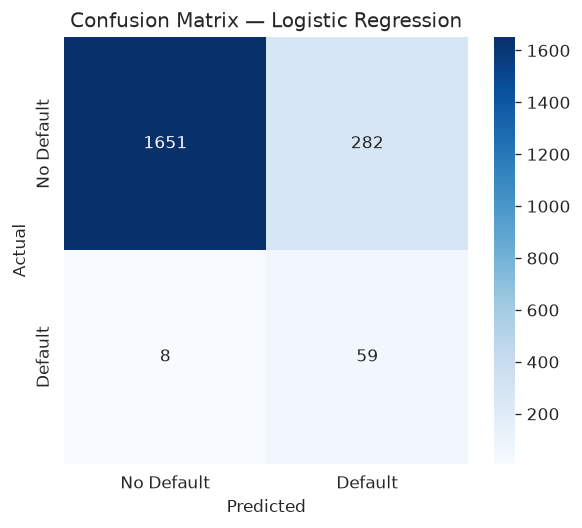

In [25]:
# Best model confusion matrix
best_model_name = results_df["roc_auc"].idxmax()
best_cm = all_models[best_model_name]["cm"]
print(f"Best model (by ROC-AUC): {best_model_name}")

fig, ax = plt.subplots(figsize=(5, 4.5))
sns.heatmap(best_cm, annot=True, fmt="d", cmap="Blues", ax=ax,
            xticklabels=["No Default", "Default"],
            yticklabels=["No Default", "Default"])
ax.set_title(f"Confusion Matrix — {best_model_name}")
ax.set_xlabel("Predicted")
ax.set_ylabel("Actual")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig11_best_confusion_matrix.png"), bbox_inches="tight")
plt.show()


## Practical 14: Feature Importance Analysis

**Aim:** Examine which features drive predictions across tree-based models and interpret logistic regression coefficients.

**Note:** Feature importance from tree models is based on the total reduction in impurity (gini/entropy) contributed by each feature across all trees. Correlation ≠ causation; these rankings suggest predictive power but not causal relationships.


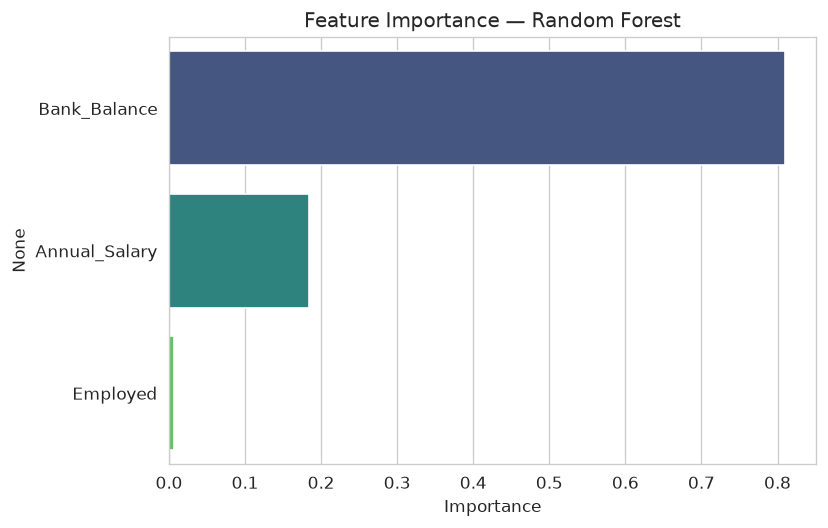

Bank_Balance     0.8101
Annual_Salary    0.1836
Employed         0.0063
dtype: float64

In [26]:
# Random Forest feature importance
rf_imp = pd.Series(rf.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=ax, palette="viridis")
ax.set_title("Feature Importance — Random Forest")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig12_feature_importance_rf.png"), bbox_inches="tight")
plt.show()
rf_imp.round(4)


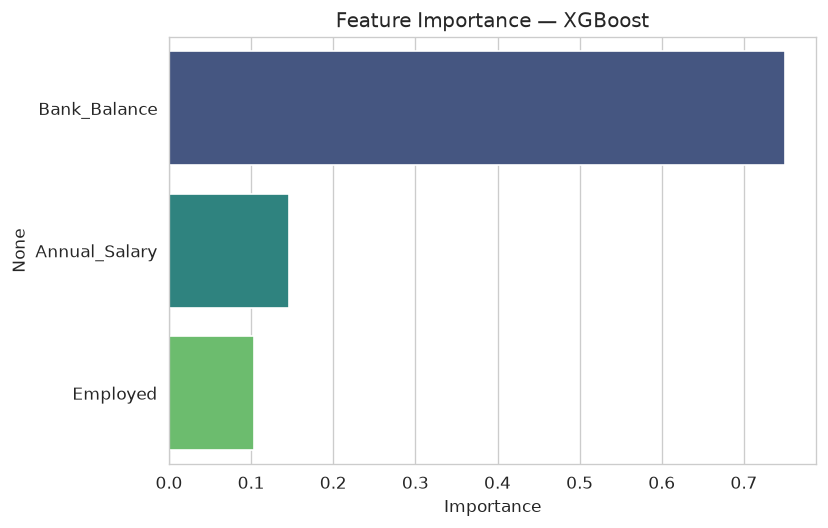

Bank_Balance     0.7503
Annual_Salary    0.1464
Employed         0.1033
dtype: float32

In [27]:
# XGBoost feature importance
xgb_imp = pd.Series(xgb.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=xgb_imp.values, y=xgb_imp.index, ax=ax, palette="viridis")
ax.set_title("Feature Importance — XGBoost")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig13_feature_importance_xgb.png"), bbox_inches="tight")
plt.show()
xgb_imp.round(4)


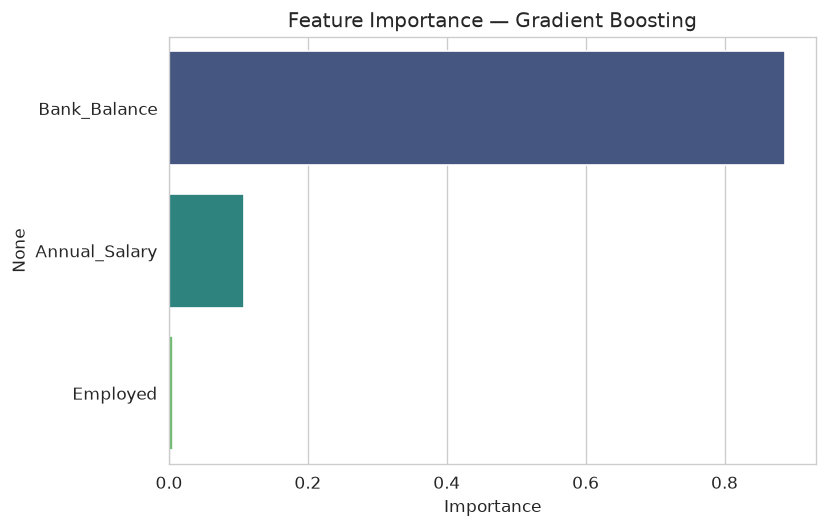

Bank_Balance     0.8874
Annual_Salary    0.1075
Employed         0.0052
dtype: float64

In [28]:
# Gradient Boosting feature importance
gb_imp = pd.Series(gb.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(7, 4.5))
sns.barplot(x=gb_imp.values, y=gb_imp.index, ax=ax, palette="viridis")
ax.set_title("Feature Importance — Gradient Boosting")
ax.set_xlabel("Importance")
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig14_feature_importance_gb.png"), bbox_inches="tight")
plt.show()
gb_imp.round(4)


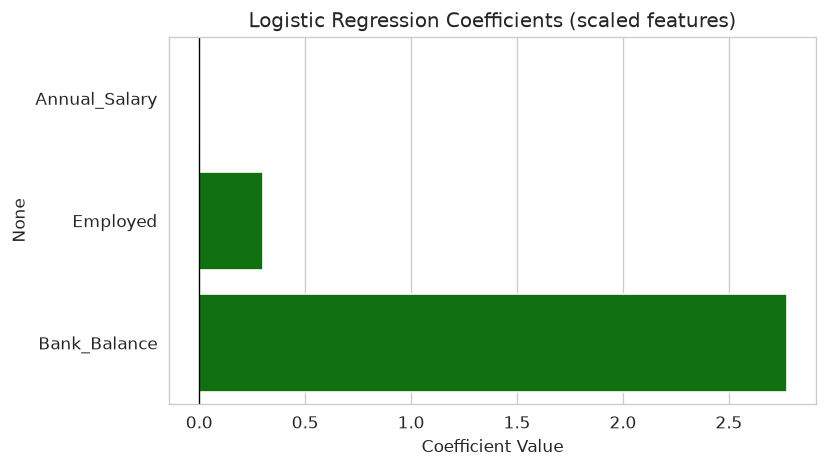

Annual_Salary   -0.0040
Employed         0.2986
Bank_Balance     2.7725
dtype: float64

In [29]:
# Logistic Regression coefficients (scaled)
lr_coef = pd.Series(logreg.coef_[0], index=X.columns).sort_values()
fig, ax = plt.subplots(figsize=(7, 4))
colors = ["red" if c < 0 else "green" for c in lr_coef.values]
sns.barplot(x=lr_coef.values, y=lr_coef.index, palette=colors, ax=ax)
ax.set_title("Logistic Regression Coefficients (scaled features)")
ax.set_xlabel("Coefficient Value")
ax.axvline(x=0, color="black", linewidth=0.8)
plt.tight_layout()
plt.savefig(os.path.join(FIG_DIR, "fig16_lr_coefficients.png"), bbox_inches="tight")
plt.show()
lr_coef.round(4)


## Practical 15: Hyperparameter Tuning with GridSearchCV

**Aim:** Optimize XGBoost hyperparameters using cross-validated grid search.

**Theory:** GridSearchCV exhaustively evaluates all hyperparameter combinations using k-fold cross-validation on the training set (preventing data leakage). The best combination is selected, then evaluated once on the held-out test set.

**Scoring metric:** `roc_auc` — robust to class imbalance.


In [30]:
param_grid = {
    "n_estimators": [100, 300],
    "max_depth": [3, 4, 5],
    "learning_rate": [0.05, 0.1],
    "subsample": [0.8, 1.0],
}

cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=RANDOM_STATE)

xgb_base = XGBClassifier(
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=RANDOM_STATE,
    verbosity=0,
)

grid_search = GridSearchCV(
    estimator=xgb_base,
    param_grid=param_grid,
    scoring="roc_auc",
    cv=cv,
    n_jobs=-1,
    verbose=0,
)
grid_search.fit(X_train, y_train)

print(f"Best parameters: {grid_search.best_params_}")
print(f"Best CV ROC-AUC: {grid_search.best_score_:.4f}")

best_xgb = grid_search.best_estimator_
y_pred_tuned = best_xgb.predict(X_test)
y_prob_tuned = best_xgb.predict_proba(X_test)[:, 1]

tuned_metrics = {
    "accuracy":  accuracy_score(y_test, y_pred_tuned),
    "precision": precision_score(y_test, y_pred_tuned, zero_division=0),
    "recall":    recall_score(y_test, y_pred_tuned, zero_division=0),
    "f1":        f1_score(y_test, y_pred_tuned, zero_division=0),
    "roc_auc":   roc_auc_score(y_test, y_prob_tuned),
}
print("\nTuned XGBoost test performance:")
for k, v in tuned_metrics.items():
    print(f"  {k}: {v:.4f}")


Best parameters: {'learning_rate': 0.05, 'max_depth': 3, 'n_estimators': 100, 'subsample': 0.8}
Best CV ROC-AUC: 0.9465

Tuned XGBoost test performance:
  accuracy: 0.8410
  precision: 0.1599
  recall: 0.8806
  f1: 0.2706
  roc_auc: 0.9432


In [31]:
# Compare baseline vs tuned XGBoost
compare_tuned = pd.DataFrame({
    "Baseline XGBoost": {k: v for k, v in xgb_metrics.items()
                         if k not in ("cm", "y_pred", "y_prob", "model")},
    "Tuned XGBoost":    tuned_metrics,
}).round(4)
compare_tuned.to_csv(os.path.join(RESULTS_DIR, "tuning_comparison.csv"))
compare_tuned


,Baseline XGBoost,Tuned XGBoost
accuracy,0.8845,0.8410
precision,0.1917,0.1599
recall,0.7612,0.8806
f1,0.3063,0.2706
roc_auc,0.9356,0.9432


## Practical 16: Cross-Validation

**Aim:** Use k-fold cross-validation to obtain more reliable performance estimates.

**Theory:** Cross-validation partitions the training data into k folds, training on k-1 folds and validating on the remaining one, repeated k times. This gives a better estimate of generalization performance than a single train/validation split.


In [32]:
cv_models = {
    "Logistic Regression": (logreg, X_train_scaled),
    "Random Forest":       (rf, X_train),
    "XGBoost":             (xgb, X_train),
}
cv_results = {}
for name, (m, X_tr) in cv_models.items():
    scores = cross_val_score(m, X_tr, y_train, cv=5, scoring="roc_auc", n_jobs=-1)
    cv_results[name] = scores
    print(f"{name:22s}: CV ROC-AUC = {scores.mean():.4f} ± {scores.std():.4f}")


Logistic Regression   : CV ROC-AUC = 0.9492 ± 0.0090


Random Forest         : CV ROC-AUC = 0.9152 ± 0.0110


XGBoost               : CV ROC-AUC = 0.9373 ± 0.0103


## Practical 17: Detailed Classification Report and Conclusion

**Aim:** Produce a full classification report (precision, recall, F1, support) for the best model and summarize findings.


In [33]:
best_y_pred = all_models[best_model_name]["y_pred"]
report = classification_report(y_test, best_y_pred,
                               target_names=["No Default", "Default"])
print(f"Best model: {best_model_name}")
print(report)


Best model: Logistic Regression
              precision    recall  f1-score   support

  No Default       1.00      0.85      0.92      1933
     Default       0.17      0.88      0.29        67

    accuracy                           0.85      2000
   macro avg       0.58      0.87      0.60      2000
weighted avg       0.97      0.85      0.90      2000



### Summary of Findings

1. **Class imbalance is critical:** Only 3.33% of customers defaulted. Accuracy alone is misleading — Random Forest achieves 96% accuracy but misses over 40% of defaulters.
2. **Best model by ROC-AUC:** Logistic Regression (AUC ≈ 0.95) achieves the highest overall ranking ability and strong recall (~88%), making it the most reliable for screening risky applicants.
3. **Most important feature:** Bank Balance dominates default prediction (≈80%+ importance across tree models), followed by Annual Salary. Employment status has minimal predictive value once balance and salary are known.
4. **Model choice depends on cost:** In production, the bank's cost of a missed default (false negative) versus a false alarm (false positive) should guide the threshold and model choice.
